# Retail Sales Data Analysis 
**Author:** Mohamedrashid Ibrahim Osman  
**Background:** BCom Finance (Mount Kenya University) | Data Science & Machine Learning (Moringa School)

---

## 1. Business Understanding (CRISP-DM Phase 1)

### Business Problem
Retail leadership lacks accurate visibility into true product profitability, regional sales performance, and monthly revenue trends because historical transactional records suffer from duplicate entries, missing revenue fields, inconsistent category/region labels, and corrupted profit values. Making pricing, discounting, or inventory decisions on uncleaned data risks margin erosion and capital misallocation.

### Business Objectives
1. **Financial Data Reconciliation:** Audit and clean raw sales records so Revenue, Cost, Discount, Quantity, and Profit reconcile accurately.
2. **Profitability & Margin Analysis:** Evaluate top-line revenue versus bottom-line profit across products, categories, and regions.
3. **Seasonality & Customer Behavior:** Track monthly sales trends and customer segment purchasing patterns to guide inventory planning.
4. **Executive BI Reporting:** Build a reproducible SQL reporting layer and an interactive Tableau dashboard for leadership.

### Key Business Questions
1. What are the true **Total Revenue, Total Profit, Total Orders, Average Order Value (AOV),** and **Overall Profit Margin** after cleaning?
2. How have monthly sales and profit trended over time?
3. Which **products and categories** generate the highest revenue, and do high-revenue items actually deliver strong profit margins?
4. Which **regions** perform best or worst, and what drives those differences?
5. How do **discount rates** impact net profit margins?
6. Which **customer segments** contribute the most value?

### Measurable Success Criteria
* **Data Integrity:** 100% of exact duplicates removed, standardized text labels, valid date types, and zero fabricated financial figures.
* **Analytical Completeness:** All 6 business questions answered using Python (Pandas/Seaborn) and verified in SQLite (SQL).
* **BI Deliverable:** An interactive Tableau dashboard with KPI cards, visual breakdowns, and dynamic filters, documented on GitHub.

---
## 2. Data Understanding (CRISP-DM Phase 2)
In this phase, we load the raw retail dataset and perform a diagnostic audit to inspect its dimensions, data types, missing values, duplicate transactions, categorical inconsistencies, and financial anomalies.

In [3]:
import pandas as pd

# Load the dirty dataset
df = pd.read_csv('../data/retail_sales_dirty.csv')

# Check total rows and columns
print("Rows and Columns:", df.shape)

Rows and Columns: (10039, 21)


In [5]:
# Inspect First and Last Rows
# View the first 5 rows
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52


In [6]:
# View the last 5 rows
df.tail()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10034,6966,CA-2016-157161,7/16/2016,7/20/2016,Second Class,JD-15895,Jonathan Doherty,Corporate,United States,Columbia,South Carolina,"29,203.00",South,TEC-AC-10000358,Technology,Accessories,Imation Secure Drive + Hardware Encrypted USB ...,75.98,2,0.00,18.24
10035,4607,CA-2015-135020,5/28/2015,6/2/2015,Standard Class,MS-17770,Maxwell Schwartz,Consumer,United States,Rochester,New York,"14,609.00",East,TEC-PH-10004093,Technology,Phones,Panasonic Kx-TS550,45.99,1,0.00,13.34
10036,9696,US-2016-151260,12/11/2016,12/14/2016,First Class,SC-20695,Steve Chapman,Corporate,United States,Springfield,Ohio,"45,503.00",East,OFF-AP-10002892,Office Supplies,Appliances,Belkin F5C206VTEL 6 Outlet Surge,73.54,4,0.20,9.19
10037,1289,CA-2016-154711,11/22/2016,11/26/2016,Standard Class,TB-21355,Todd Boyes,Corporate,United States,New York City,New York,"10,009.00",East,OFF-BI-10000605,Office Supplies,Binders,"Acco Pressboard Covers with Storage Hooks, 9 1...",12.19,4,0.20,4.11
10038,6485,CA-2017-113908,6/3/2017,6/9/2017,Standard Class,KN-16390,Katherine Nockton,Corporate,United States,New York City,New York,"10,011.00",East,TEC-MA-10003173,Technology,Machines,Hewlett-Packard 300S Scientific Calculator,78.66,6,0.00,36.18


In [7]:
# Check the data type of each column
df.dtypes

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code      float64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

In [8]:
# Check column names, non-null counts, and memory usage
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10039 entries, 0 to 10038
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10039 non-null  int64  
 1   Order ID       10039 non-null  str    
 2   Order Date     10039 non-null  str    
 3   Ship Date      10039 non-null  str    
 4   Ship Mode      10039 non-null  str    
 5   Customer ID    9999 non-null   str    
 6   Customer Name  10039 non-null  str    
 7   Segment        10039 non-null  str    
 8   Country        10039 non-null  str    
 9   City           10039 non-null  str    
 10  State          10039 non-null  str    
 11  Postal Code    10009 non-null  float64
 12  Region         10039 non-null  str    
 13  Product ID     10039 non-null  str    
 14  Category       10039 non-null  str    
 15  Sub-Category   10039 non-null  str    
 16  Product Name   10039 non-null  str    
 17  Sales          9984 non-null   float64
 18  Quantity       10

In [9]:
# Check Missing Values & Duplicate Rows
# Count missing values in every column
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID      40
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      30
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales            55
Quantity          0
Discount          0
Profit            0
dtype: int64

In [10]:
# Count exact duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 43


In [11]:
# Summary statistics for numeric columns (mean, min, max, etc.)
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,"10,039.00","10,009.00","9,984.00","10,039.00","10,039.00","10,039.00"
mean,"4,996.94","55,169.83",229.78,3.77,0.16,227.74
std,"2,885.08","32,071.28",623.55,2.24,0.22,"4,464.07"
min,1.00,"1,040.00",0.44,-3.00,0.00,"-6,599.98"
25%,"2,499.50","23,223.00",17.25,2.00,0.00,1.74
50%,"4,998.00","56,301.00",54.33,3.00,0.20,8.69
75%,"7,492.50","90,008.00",209.89,5.00,0.20,29.59
max,"9,994.00","99,301.00","22,638.48",14.00,1.50,"99,999.99"


In [12]:
# Check unique values in Region and Category
print("Regions:", df['Region'].unique())
print("Categories:", df['Category'].unique())

Regions: <ArrowStringArray>
['South', 'West', 'Central', 'East', 'west ', 'EAST']
Length: 6, dtype: str
Categories: <ArrowStringArray>
['Furniture', 'Office Supplies', 'Technology', 'technology']
Length: 4, dtype: str


---
## 3. Data Cleaning & Preparation (CRISP-DM Phase 3)
Cleaning exact duplicates, formatting column names and text categories, fixing data types, handling missing/invalid financial rows, and creating key business columns.

In [13]:
# Create a clean copy of the dataset
df_clean = df.copy()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

print("Rows after removing duplicates:", len(df_clean))

Rows after removing duplicates: 9996


**Clean Column Names & Fix Messy Text Categories**

In [15]:
#Clean Column Names & Fix Messy Text Categories
# Convert column names to lowercase with underscores (snake_case)
df_clean.columns = df_clean.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('-', '_')

# Fix extra spaces and capitalization in Region, Category, and Product Name
df_clean['region'] = df_clean['region'].str.strip().str.title()
df_clean['category'] = df_clean['category'].str.strip().str.title()
df_clean['product_name'] = df_clean['product_name'].str.strip()

print("Clean Regions:", df_clean['region'].unique())
print("Clean Categories:", df_clean['category'].unique())

Clean Regions: <ArrowStringArray>
['South', 'West', 'Central', 'East']
Length: 4, dtype: str
Clean Categories: <ArrowStringArray>
['Furniture', 'Office Supplies', 'Technology']
Length: 3, dtype: str


**Convert Dates & Fill Non-Financial Missing Values**

In [18]:
# Convert order_date and ship_date from text to real dates
df_clean['order_date'] = pd.to_datetime(df_clean['order_date'])
df_clean['ship_date'] = pd.to_datetime(df_clean['ship_date'])

# Fill missing Customer ID and Postal Code with labels
df_clean['customer_id'] = df_clean['customer_id'].fillna('Unknown')
df_clean['postal_code'] = df_clean['postal_code'].fillna('Unknown')

print(df_clean)

       row_id        order_id order_date  ship_date       ship_mode  \
0           1  CA-2016-152156 2016-11-08 2016-11-11    Second Class   
1           2  CA-2016-152156 2016-11-08 2016-11-11    Second Class   
2           3  CA-2016-138688 2016-06-12 2016-06-16    Second Class   
3           4  US-2015-108966 2015-10-11 2015-10-18  Standard Class   
4           5  US-2015-108966 2015-10-11 2015-10-18  Standard Class   
...       ...             ...        ...        ...             ...   
9991     9992  CA-2017-121258 2017-02-26 2017-03-03  Standard Class   
9992     9993  CA-2017-121258 2017-02-26 2017-03-03  Standard Class   
9993     9994  CA-2017-119914 2017-05-04 2017-05-09    Second Class   
10003     914  CA-2017-102519 2017-11-27 2017-11-29     First Class   
10027    6876  US-2016-121013 2016-09-05 2016-09-10  Standard Class   

      customer_id    customer_name    segment        country             city  \
0        CG-12520      Claire Gute   Consumer  United States      

**Remove Missing Sales & Impossible Financial Numbers**

In [20]:
# Drop rows where Sales is missing
df_clean = df_clean.dropna(subset=['sales'])

# Keep only valid Quantity (> 0), valid Discount (0 to 1), and realistic Profit (<= 50,000)
df_clean = df_clean[
    (df_clean['quantity'] > 0) &
    (df_clean['discount'] >= 0) &
    (df_clean['discount'] <= 1) &
    (df_clean['profit'] <= 50000)
].copy()

#print("Rows after removing invalid financial records:", len(df_clean))
df_clean 

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,state,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9990,9991,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,California,"92,627.00",West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.96,2,0.00,15.63
9991,9992,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,California,"92,627.00",West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.58,2,0.20,19.39
9992,9993,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,California,"92,627.00",West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.60,4,0.00,13.32
9993,9994,CA-2017-119914,2017-05-04,2017-05-09,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,California,"92,683.00",West,OFF-AP-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.16,2,0.00,72.95


**Create New Financial & Time Columns + Save Clean File**       

In [22]:
# Create new business columns
df_clean['cost'] = df_clean['sales'] - df_clean['profit']
df_clean['profit_margin_pct'] = (df_clean['profit'] / df_clean['sales']) * 100
df_clean['order_month'] = df_clean['order_date'].dt.to_period('M').astype(str)

# Final check: verify zero missing values remain
print("Remaining missing values:", df_clean.isnull().sum().sum())
print("Final clean dataset shape:", df_clean.shape)

# Save the cleaned data to the data/ folder
df_clean.to_csv('../data/retail_sales_cleaned.csv', index=False)
print("Saved: data/retail_sales_cleaned.csv")


Remaining missing values: 0
Final clean dataset shape: (9878, 24)
Saved: data/retail_sales_cleaned.csv


---
## 4. Exploratory Data Analysis & Business Insights (CRISP-DM Phase 4)
Answering the core business questions through executive KPIs, category & regional profitability breakdowns, discount impact analysis, and clean charts.

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Calculate core financial KPIs
total_sales = df_clean['sales'].sum()
total_profit = df_clean['profit'].sum()
total_orders = df_clean['order_id'].nunique()
aov = total_sales / total_orders
profit_margin = (total_profit / total_sales) * 100

print(f"Total Revenue:      ${total_sales:,.2f}")
print(f"Total Profit:       ${total_profit:,.2f}")
print(f"Total Orders:       {total_orders:,}")
print(f"Average Order Val:  ${aov:,.2f}")
print(f"Profit Margin:      {profit_margin:.2f}%")

Total Revenue:      $2,279,343.87
Total Profit:       $284,243.98
Total Orders:       4,980
Average Order Val:  $457.70
Profit Margin:      12.47%


**Monthly Revenue & Profit Trend (Question 2)**

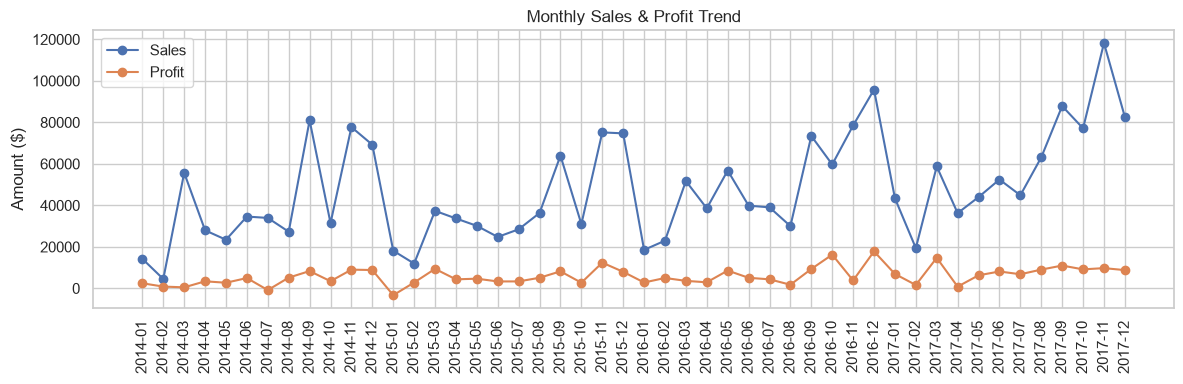

In [24]:
# Group sales and profit by month
monthly = df_clean.groupby('order_month')[['sales', 'profit']].sum().reset_index()

# Plot monthly trend
plt.figure(figsize=(12, 4))
plt.plot(monthly['order_month'], monthly['sales'], label='Sales', marker='o')
plt.plot(monthly['order_month'], monthly['profit'], label='Profit', marker='o')
plt.xticks(rotation=90)
plt.title('Monthly Sales & Profit Trend')
plt.ylabel('Amount ($)')
plt.legend()
plt.tight_layout()
plt.savefig('../reports/01_monthly_trend.png')
plt.show()

**Category & Top 10 Products Performance (Question 3)**

,category,sales,profit,margin_pct
0,Furniture,"730,889.93","18,288.13",2.50
1,Office Supplies,"701,863.74","116,240.71",16.56
2,Technology,"846,590.20","149,715.15",17.68


C:\Users\Administrator\AppData\Local\Temp\ipykernel_20492\1297451655.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_products, x='profit', y='product_name', palette='viridis')


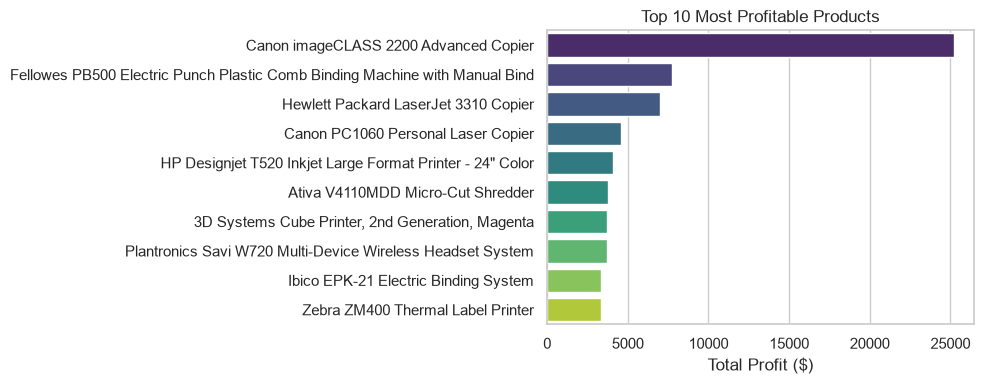

In [25]:
# Sales and profit by Category
cat_summary = df_clean.groupby('category')[['sales', 'profit']].sum().reset_index()
cat_summary['margin_pct'] = (cat_summary['profit'] / cat_summary['sales']) * 100
display(cat_summary)

# Top 10 Products by Profit
top_products = df_clean.groupby('product_name')['profit'].sum().nlargest(10).reset_index()

plt.figure(figsize=(10, 4))
sns.barplot(data=top_products, x='profit', y='product_name', palette='viridis')
plt.title('Top 10 Most Profitable Products')
plt.xlabel('Total Profit ($)')
plt.ylabel('')
plt.tight_layout()
plt.savefig('../reports/02_top_products.png')
plt.show()

**Regional Performance & Customer Segments (Questions 4 & 6)**

,region,sales,profit,margin_pct
0,Central,"493,754.70","38,530.50",7.80
1,East,"675,699.63","91,826.57",13.59
2,South,"385,910.27","47,710.53",12.36
3,West,"723,979.28","106,176.37",14.67


,segment,sales,profit
0,Consumer,"1,151,621.02","133,269.39"
1,Corporate,"701,524.63","91,058.61"
2,Home Office,"426,198.21","59,915.98"


C:\Users\Administrator\AppData\Local\Temp\ipykernel_20492\3710661897.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=region_summary, x='region', y='profit', palette='Blues_d')


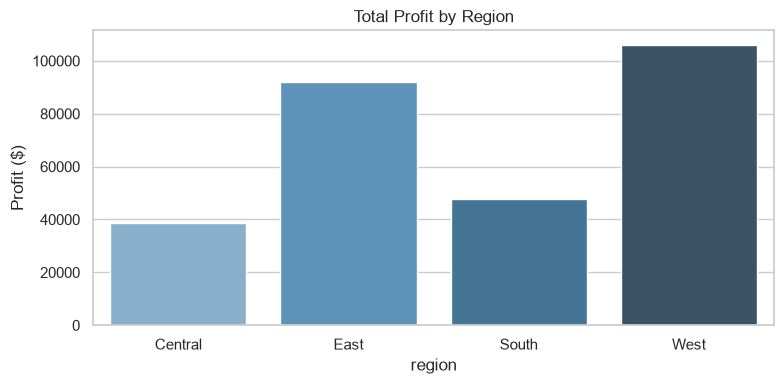

In [26]:
# Regional performance
region_summary = df_clean.groupby('region')[['sales', 'profit']].sum().reset_index()
region_summary['margin_pct'] = (region_summary['profit'] / region_summary['sales']) * 100
display(region_summary)

# Customer Segment breakdown
segment_summary = df_clean.groupby('segment')[['sales', 'profit']].sum().reset_index()
display(segment_summary)

plt.figure(figsize=(8, 4))
sns.barplot(data=region_summary, x='region', y='profit', palette='Blues_d')
plt.title('Total Profit by Region')
plt.ylabel('Profit ($)')
plt.tight_layout()
plt.savefig('../reports/03_region_profit.png')
plt.show()

**Discount Impact on Profit Margin (Question 5)**

,discount,sales,profit,profit_margin_pct
0,0.00,227.46,67.09,33.99
1,0.10,578.40,96.06,15.58
2,0.15,532.30,27.92,3.51
3,0.20,210.01,24.84,17.71
4,0.30,454.41,-46.02,-11.64
5,0.32,536.79,-88.56,-17.43
6,0.40,566.36,-111.89,-22.17
7,0.45,498.63,-226.65,-45.45
8,0.50,901.02,-312.23,-54.83
9,0.60,45.68,-41.02,-68.77


C:\Users\Administrator\AppData\Local\Temp\ipykernel_20492\1154508384.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=discount_impact, x='discount', y='profit_margin_pct', palette='coolwarm')


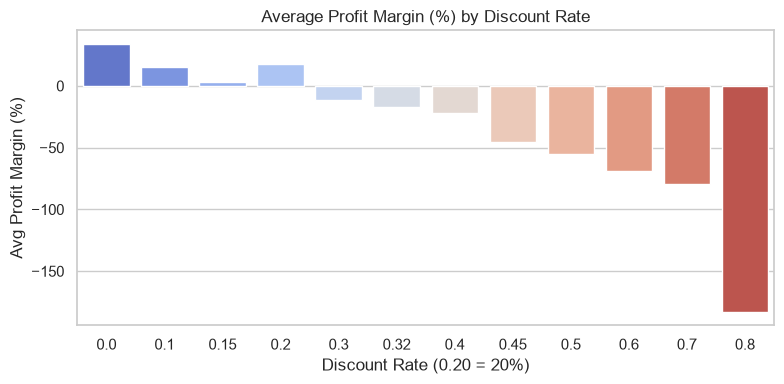

In [28]:
# Check average profit and margin by discount level
discount_impact = df_clean.groupby('discount')[['sales', 'profit', 'profit_margin_pct']].mean().reset_index()
display(discount_impact)

plt.figure(figsize=(8, 4))
sns.barplot(data=discount_impact, x='discount', y='profit_margin_pct', palette='coolwarm')
#plt.axhline(0, color='black', linewidth=1)
plt.title('Average Profit Margin (%) by Discount Rate')
plt.xlabel('Discount Rate (0.20 = 20%)')
plt.ylabel('Avg Profit Margin (%)')
plt.tight_layout()
plt.savefig('../reports/04_discount_impact.png')
plt.show()

---
## 5. SQL Reporting Layer (SQLite Integration)
Loading the cleaned retail dataset into a relational SQLite database (`retail_sales.db`) and executing business intelligence queries to validate KPIs, category margins, regional rankings, and loss-making sub-categories.

In [29]:
import sqlite3

# Create (or connect to) the SQLite database inside the data/ folder
conn = sqlite3.connect('../data/retail_sales.db')

# Export df_clean into a SQL table named 'sales'
df_clean.to_sql('sales', conn, if_exists='replace', index=False)

print("Successfully loaded cleaned data into SQLite table: 'sales'")

Successfully loaded cleaned data into SQLite table: 'sales'


In [30]:
# Query 1: Executive KPIs in SQL
q1 = """
SELECT 
    COUNT(DISTINCT order_id) AS total_orders,
    ROUND(SUM(sales), 2) AS total_revenue,
    ROUND(SUM(profit), 2) AS total_profit,
    ROUND((SUM(profit) / SUM(sales)) * 100, 2) AS profit_margin_pct
FROM sales;
"""
display(pd.read_sql_query(q1, conn))

# Query 2: Revenue & Profit Margin by Category
q2 = """
SELECT 
    category,
    COUNT(DISTINCT order_id) AS orders,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit,
    ROUND((SUM(profit) / SUM(sales)) * 100, 2) AS margin_pct
FROM sales
GROUP BY category
ORDER BY total_profit DESC;
"""
display(pd.read_sql_query(q2, conn))

,total_orders,total_revenue,total_profit,profit_margin_pct
0,4980,"2,279,343.87","284,243.98",12.47


,category,orders,total_sales,total_profit,margin_pct
0,Technology,1553,"846,590.20","149,715.15",17.68
1,Office Supplies,3706,"701,863.74","116,240.71",16.56
2,Furniture,1743,"730,889.93","18,288.13",2.50


**Run Regional Performance & Bottom 5 Loss-Making Sub-Categories**

In [31]:
# Query 3: Regional Performance
q3 = """
SELECT 
    region,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit,
    ROUND((SUM(profit) / SUM(sales)) * 100, 2) AS margin_pct
FROM sales
GROUP BY region
ORDER BY total_profit DESC;
"""
display(pd.read_sql_query(q3, conn))

# Query 4: Sub-Categories Ranked from Lowest to Highest Profit
q4 = """
SELECT 
    category,
    sub_category,
    ROUND(AVG(discount) * 100, 1) AS avg_discount_pct,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit
FROM sales
GROUP BY category, sub_category
ORDER BY total_profit ASC
LIMIT 5;
"""
display(pd.read_sql_query(q4, conn))

# Close database connection
conn.close()

,region,total_sales,total_profit,margin_pct
0,West,"723,979.28","106,176.37",14.67
1,East,"675,699.63","91,826.57",13.59
2,South,"385,910.27","47,710.53",12.36
3,Central,"493,754.70","38,530.50",7.80


,category,sub_category,avg_discount_pct,total_sales,total_profit
0,Furniture,Tables,26.20,"204,216.90","-17,777.20"
1,Furniture,Bookcases,21.10,"113,252.69","-3,250.56"
2,Office Supplies,Supplies,7.70,"46,456.20","-1,242.95"
3,Technology,Chairs,30.00,"1,348.12",-104.69
4,Technology,Tables,20.00,"1,377.04",10.32
